**Estandarización de las variables**

En este notebook se estandarizan las variables ICEN, ONI, SSN y precipitación ERA5 mediante puntuaciones Z.

La transformación permite expresar las variables en una escala comparable, conservando los datos originales sin modificación.

La estandarización se define como:

z = (x - μ) / σ

donde x representa el valor original, μ la media y σ la desviación estándar de la variable

In [1]:
import os
import subprocess

repo = "correlacion_actividad_solar_elnino"
ruta_repo = f"/content/{repo}"

if not os.path.exists(ruta_repo):
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/gretadive/correlacion_actividad_solar_elnino.git"
        ],
        check=True
    )
    print("✅ Repositorio clonado correctamente")
else:
    print("✅ El repositorio ya está disponible")

✅ Repositorio clonado correctamente


In [2]:
%cd /content/correlacion_actividad_solar_elnino

/content/correlacion_actividad_solar_elnino


In [3]:
!ls data/processed

dataset_integrado.csv		     precipitacion.ERA5_procesado.csv
dataset_integrado_precipitacion.csv  README.md
icen_procesado.csv		     ssn_procesado.csv
oni_procesado.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = pd.read_csv(
    "data/processed/dataset_integrado_precipitacion.csv",
    parse_dates=["fecha"]
)

dataset.head()

,fecha,anio,mes,ICEN,ONI,SSN,precipitacion_mm
0,1950-01-01,1950,1,-0.75,-1.32,143.9,155.309817
1,1950-02-01,1950,2,-1.07,-1.20,134.3,164.955825
2,1950-03-01,1950,3,-1.25,-1.12,155.4,158.180623
3,1950-04-01,1950,4,-1.18,-1.08,160.6,221.687990
4,1950-05-01,1950,5,-1.22,-1.10,150.5,123.802819


In [5]:
variables = ["ICEN","ONI","SSN","precipitacion_mm"]
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

datos_estandarizados = scaler.fit_transform(
    dataset[variables]
)

dataset_std = dataset.copy()

dataset_std["ICEN_z"] = datos_estandarizados[:, 0]
dataset_std["ONI_z"] = datos_estandarizados[:, 1]
dataset_std["SSN_z"] = datos_estandarizados[:, 2]
dataset_std["precipitacion_z"] = datos_estandarizados[:, 3]

dataset_std.head()

,fecha,anio,mes,ICEN,ONI,SSN,precipitacion_mm,ICEN_z,ONI_z,SSN_z,precipitacion_z
0,1950-01-01,1950,1,-0.75,-1.32,143.9,155.309817,-0.739281,-1.701931,0.714512,0.184420
1,1950-02-01,1950,2,-1.07,-1.20,134.3,164.955825,-1.053560,-1.548973,0.584052,0.306607
2,1950-03-01,1950,3,-1.25,-1.12,155.4,158.180623,-1.230343,-1.447000,0.870792,0.220785
3,1950-04-01,1950,4,-1.18,-1.08,160.6,221.687990,-1.161594,-1.396014,0.941458,1.025240
4,1950-05-01,1950,5,-1.22,-1.10,150.5,123.802819,-1.200879,-1.421507,0.804203,-0.214682


In [6]:
columnas_z = ["ICEN_z","ONI_z","SSN_z","precipitacion_z"]
dataset_std[columnas_z].describe().T
for variable in columnas_z:
    print(
        variable,
        "| Media:",
        round(dataset_std[variable].mean(), 6),
        "| Desv. estándar:",
        round(dataset_std[variable].std(), 4)
    )

ICEN_z | Media: -0.0 | Desv. estándar: 1.0005
ONI_z | Media: 0.0 | Desv. estándar: 1.0005
SSN_z | Media: 0.0 | Desv. estándar: 1.0005
precipitacion_z | Media: 0.0 | Desv. estándar: 1.0005


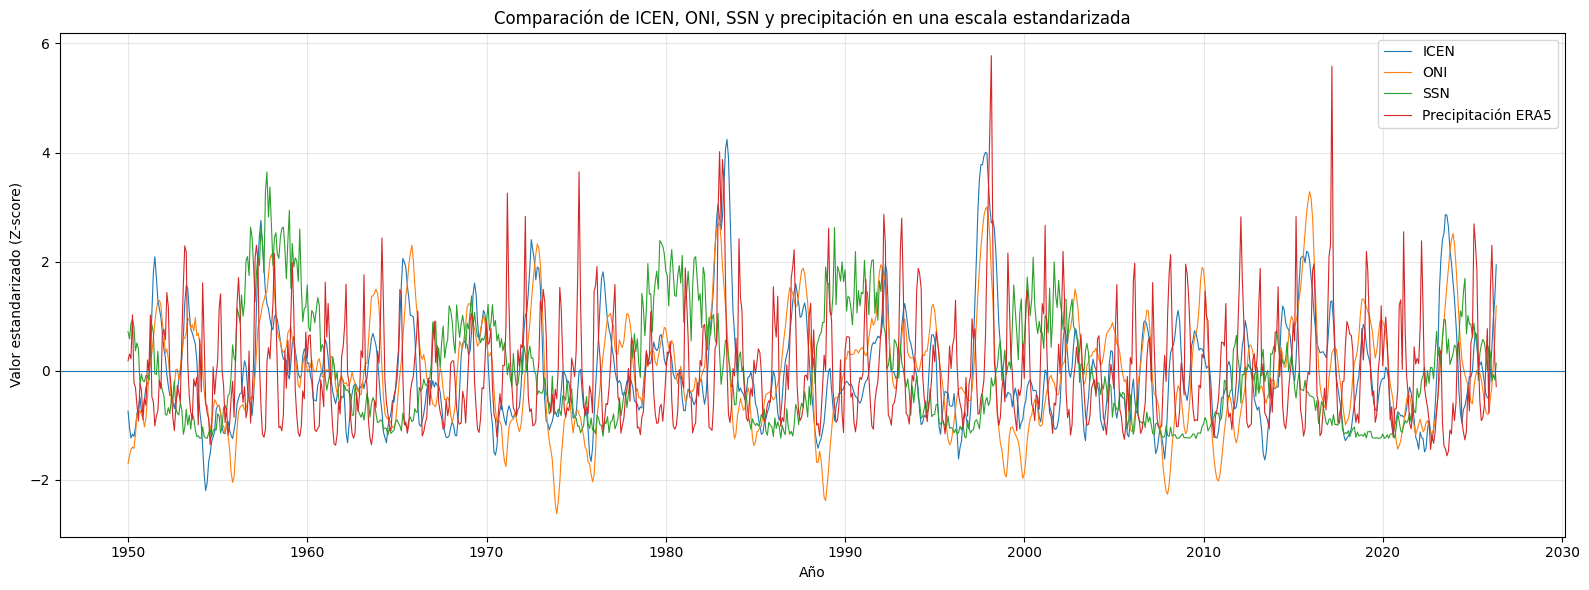

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,6))

plt.plot(
    dataset_std["fecha"],
    dataset_std["ICEN_z"],
    label="ICEN",
    linewidth=0.8
)

plt.plot(
    dataset_std["fecha"],
    dataset_std["ONI_z"],
    label="ONI",
    linewidth=0.8
)

plt.plot(
    dataset_std["fecha"],
    dataset_std["SSN_z"],
    label="SSN",
    linewidth=0.8
)

plt.plot(
    dataset_std["fecha"],
    dataset_std["precipitacion_z"],
    label="Precipitación ERA5",
    linewidth=0.8
)

plt.axhline(0, linewidth=0.8)

plt.xlabel("Año")
plt.ylabel("Valor estandarizado (Z-score)")
plt.title(
    "Comparación de ICEN, ONI, SSN y precipitación en una escala estandarizada"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

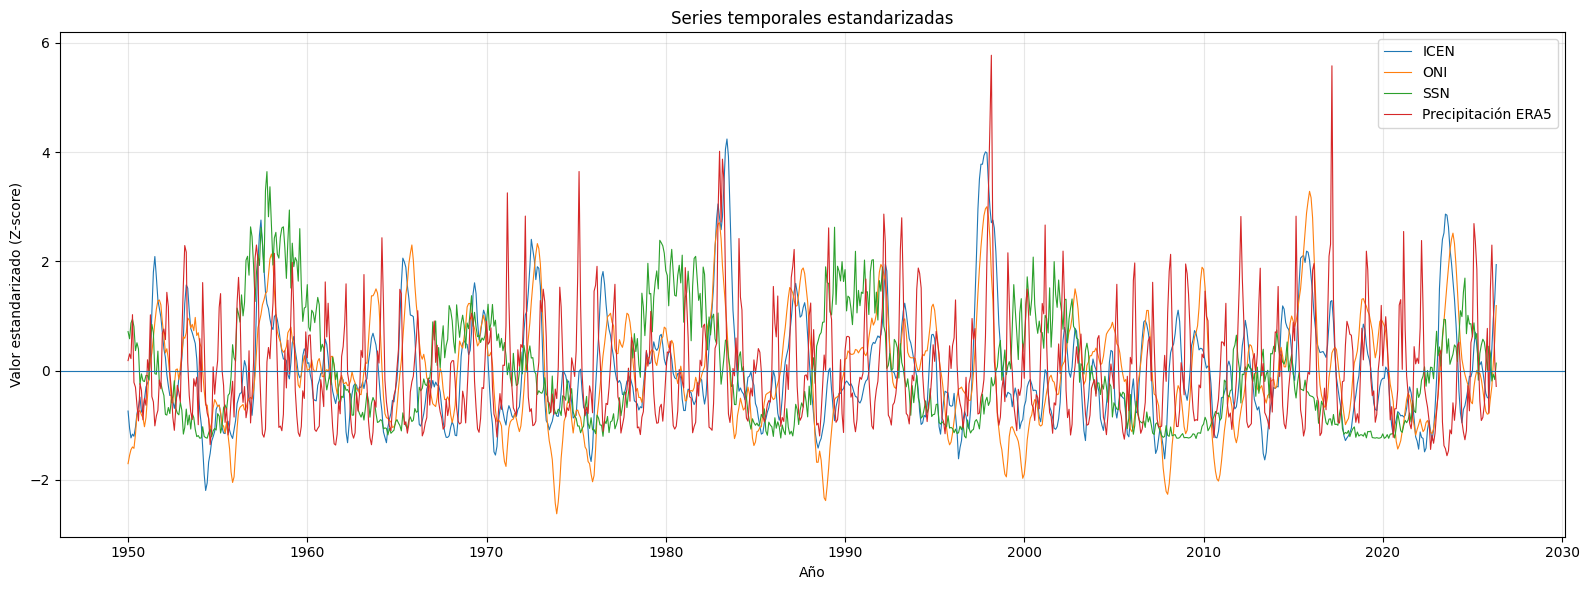

In [8]:
plt.figure(figsize=(16,6))

plt.plot(dataset_std["fecha"], dataset_std["ICEN_z"], label="ICEN", linewidth=0.8)
plt.plot(dataset_std["fecha"], dataset_std["ONI_z"], label="ONI", linewidth=0.8)
plt.plot(dataset_std["fecha"], dataset_std["SSN_z"], label="SSN", linewidth=0.8)
plt.plot(dataset_std["fecha"], dataset_std["precipitacion_z"], label="Precipitación ERA5", linewidth=0.8)

plt.axhline(0, linewidth=0.8)
plt.xlabel("Año")
plt.ylabel("Valor estandarizado (Z-score)")
plt.title("Series temporales estandarizadas")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/series_estandarizadas_zscore.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
dataset_std.to_csv(
    "data/processed/dataset_estandarizado.csv",
    index=False,
    encoding="utf-8"
)

print("✅ Dataset estandarizado guardado correctamente")

✅ Dataset estandarizado guardado correctamente


## Resultado de la estandarización

Las variables ICEN, ONI, SSN y precipitación ERA5 presentan magnitudes y unidades diferentes. Para facilitar su comparación conjunta se aplicó una estandarización mediante puntuaciones Z.

Después de la transformación, cada variable presenta una media cercana a cero y una desviación estándar cercana a uno. Esto permite analizar sus variaciones relativas en una escala común sin reemplazar ni modificar los valores originales.